# 02. Market Basket Analysis & Product Association Mining

**Lead Responsible**: Obesekara S.O.K.D (`IT24103866`)  
**Module**: IT3091 – Machine Learning | Group 2026-AI-15  
**Track**: Industry Explorer Track  

---

## Objectives
1. Transform processed transaction records into one-hot basket matrix format.
2. Execute **FP-Growth** as the baseline algorithm on transaction baskets.
3. Benchmark runtime and memory footprint against **Apriori** and **ECLAT**.
4. Prune trivial associations and evaluate rules using Support, Confidence, Lift (> 1.0), and Conviction.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
from src.basket_transformer import create_one_hot_basket
from src.association_engine import extract_frequent_itemsets, generate_pruned_rules

print("Market Basket Analysis environment ready.")

Market Basket Analysis environment ready.


In [2]:
import sys
import time
import tracemalloc
from pathlib import Path

# Resolve project root dynamically
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# MLxtend frequent patterns and association rules
from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules

# Project modular imports
from src.utils import setup_plot_style, save_figure, export_summary_table

# Apply consistent publication theme
setup_plot_style()

print(f"[OK] Python Interpreter : {sys.executable}")
print(f"[OK] Project Root       : {PROJECT_ROOT}")

[OK] Python Interpreter : C:\Users\dinid\Downloads\supermarket-basket-reorder-analytics\.venv\Scripts\python.exe
[OK] Project Root       : C:\Users\dinid\Downloads\supermarket-basket-reorder-analytics


## 1. Ingestion of Master Cleaned Transactions
Load `data/processed/cleaned_transactions.parquet` and compute basket structural metrics.

In [3]:
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "cleaned_transactions.parquet"
assert DATA_FILE.exists(), f"Missing processed data at {DATA_FILE}."

df = pd.read_parquet(DATA_FILE)
total_orders = df["order_id"].nunique()
total_products = df["product_name"].nunique()

print("TRANSACTION BASKET DIAGNOSTIC AUDIT")
print(f"Total Transactions Loaded : {len(df):,} line items")
print(f"Total Unique Baskets      : {total_orders:,} orders")
print(f"Total Product Universe    : {total_products} distinct categories")
print(f"Average Items Per Basket  : {len(df) / total_orders:.2f} items")

TRANSACTION BASKET DIAGNOSTIC AUDIT
Total Transactions Loaded : 2,019,501 line items
Total Unique Baskets      : 200,000 orders
Total Product Universe    : 134 distinct categories
Average Items Per Basket  : 10.10 items


## 2. Construction of Binary Transaction Basket Matrix
Market Basket Analysis requires a 2D binary indicator matrix where:
* Rows represent distinct checkout transactions (`order_id`).
* Columns represent distinct product categories (`product_name`).
* Cell value is `True` ($1$) if the product was present in the basket, else `False` ($0$).

In [4]:
print("Constructing One-Hot Basket Matrix...")
start_t = time.time()

# Group by order_id and product_name, converting count > 0 to boolean
basket = (
    df.groupby(["order_id", "product_name"], observed=False)["product_name"]
    .count()
    .unstack()
    .fillna(0)
)

# Convert to memory-efficient boolean matrix
basket_bool = basket > 0

elapsed_pivot = time.time() - start_t
mem_mb = basket_bool.memory_usage(deep=True).sum() / (1024 ** 2)

# Matrix Sparsity Calculation: % of matrix cells that are False (0)
non_zero_cells = basket_bool.values.sum()
total_cells = basket_bool.shape[0] * basket_bool.shape[1]
sparsity = (1 - (non_zero_cells / total_cells)) * 100

print(f"[SUCCESS] Basket Matrix Shape : {basket_bool.shape[0]:,} Orders x {basket_bool.shape[1]} Products")
print(f"Memory Footprint      : {mem_mb:.2f} MB | Transformation Time: {elapsed_pivot:.2f}s")
print(f"Matrix Sparsity       : {sparsity:.2f}% (Typical for retail basket data)")

basket_bool.iloc[:5, :8]

Constructing One-Hot Basket Matrix...
[SUCCESS] Basket Matrix Shape : 200,000 Orders x 134 Products
Memory Footprint      : 26.32 MB | Transformation Time: 4.03s
Matrix Sparsity       : 94.58% (Typical for retail basket data)


product_name,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor
order_id,,,,,,,,
10,False,False,False,False,True,False,False,False
11,False,False,False,False,False,False,False,False
28,False,False,False,False,False,False,False,False
38,False,False,False,False,False,False,False,False
56,False,False,False,False,False,False,False,False


## 3. Baseline Algorithm Execution: Frequent Pattern Growth (FP-Growth)
FP-Growth compresses the transaction database into a compact **FP-Tree (Frequent Pattern Tree)**

In [5]:
MIN_SUPPORT = 0.015  # Item must appear in at least 1.5% of all baskets (3,000+ orders)

print(f"Executing FP-Growth on {len(basket_bool):,} orders (min_support={MIN_SUPPORT})...")
t0 = time.time()
frequent_itemsets_fp = fpgrowth(basket_bool, min_support=MIN_SUPPORT, use_colnames=True)
fp_duration = time.time() - t0

# Add itemset length column
frequent_itemsets_fp["length"] = frequent_itemsets_fp["itemsets"].apply(lambda x: len(x))

print(f" FP-Growth completed in {fp_duration:.3f} seconds.")
print(f"Total Frequent Itemsets Discovered: {len(frequent_itemsets_fp):,}")

# Breakdown by itemset length
print("\nItemset Length Breakdown:")
print(frequent_itemsets_fp["length"].value_counts().sort_index())

frequent_itemsets_fp.sort_values(by="support", ascending=False).head(10)

Executing FP-Growth on 200,000 orders (min_support=0.015)...
 FP-Growth completed in 3.807 seconds.
Total Frequent Itemsets Discovered: 1,390

Itemset Length Breakdown:
length
1     85
2    490
3    553
4    228
5     33
6      1
Name: count, dtype: int64


,support,itemsets,length
0,0.555995,frozenset({fresh fruits}),1
1,0.444360,frozenset({fresh vegetables}),1
18,0.365415,frozenset({packaged vegetables fruits}),1
85,0.317560,"frozenset({fresh fruits, fresh vegetables})",2
450,0.269870,"frozenset({packaged vegetables fruits, fresh f...",2
11,0.263675,frozenset({yogurt}),1
12,0.243325,frozenset({milk}),1
449,0.234555,"frozenset({packaged vegetables fruits, fresh v...",2
13,0.230995,frozenset({packaged cheese}),1
26,0.193005,frozenset({water seltzer sparkling water}),1


## 4. Algorithmic Benchmarking: FP-Growth vs. Apriori vs. ECLAT
To satisfy university evaluation requirements, we benchmark our baseline **FP-Growth** against **Apriori** (breadth-first candidate generation) and an implementation of **ECLAT**

In [6]:
def run_eclat(basket_df: pd.DataFrame, min_support: float = 0.02) -> pd.DataFrame:
    """
    Vertical tidset intersection mining (ECLAT algorithm).
    """
    min_count = min_support * len(basket_df)
    # Build vertical tidsets (item -> set of transaction indices)
    tidsets = {col: set(np.where(basket_df[col].values)[0]) for col in basket_df.columns}
    frequent_1 = {frozenset([item]): tids for item, tids in tidsets.items() if len(tids) >= min_count}
    
    # 2-itemsets intersection
    results = []
    for itemset, tids in frequent_1.items():
        results.append({"itemsets": itemset, "support": len(tids) / len(basket_df)})
        
    items = list(frequent_1.keys())
    for i in range(len(items)):
        for j in range(i + 1, len(items)):
            combined_tids = frequent_1[items[i]] & frequent_1[items[j]]
            if len(combined_tids) >= min_count:
                results.append({
                    "itemsets": items[i] | items[j],
                    "support": len(combined_tids) / len(basket_df)
                })
    return pd.DataFrame(results)

# Benchmarking harness across 50,000 sample orders
benchmark_sample = basket_bool.sample(50000, random_state=42)
test_supports = [0.03, 0.02, 0.015]

bench_results = []

for supp in test_supports:
    # 1. FP-Growth
    tracemalloc.start()
    t_start = time.time()
    res_fp = fpgrowth(benchmark_sample, min_support=supp, use_colnames=True)
    t_fp = time.time() - t_start
    _, mem_fp = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # 2. Apriori
    tracemalloc.start()
    t_start = time.time()
    res_ap = apriori(benchmark_sample, min_support=supp, use_colnames=True)
    t_ap = time.time() - t_start
    _, mem_ap = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # 3. ECLAT
    tracemalloc.start()
    t_start = time.time()
    res_ec = run_eclat(benchmark_sample, min_support=supp)
    t_ec = time.time() - t_start
    _, mem_ec = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    bench_results.append({
        "min_support": supp,
        "itemsets_count": len(res_fp),
        "fp_growth_time_sec": round(t_fp, 4),
        "apriori_time_sec": round(t_ap, 4),
        "eclat_time_sec": round(t_ec, 4),
        "speedup_fp_vs_apriori": round(t_ap / t_fp, 2),
        "fp_growth_ram_mb": round(mem_fp / (1024**2), 2),
        "apriori_ram_mb": round(mem_ap / (1024**2), 2),
        "eclat_ram_mb": round(mem_ec / (1024**2), 2)
    })

df_bench = pd.DataFrame(bench_results)
export_summary_table(df_bench, "algorithm_benchmark_fpgrowth_vs_apriori_vs_eclat.csv")
display(df_bench)

[Exported Table]  -> reports\tables\algorithm_benchmark_fpgrowth_vs_apriori_vs_eclat.csv


,min_support,itemsets_count,fp_growth_time_sec,apriori_time_sec,eclat_time_sec,speedup_fp_vs_apriori,fp_growth_ram_mb,apriori_ram_mb,eclat_ram_mb
0,0.030,391,3.6282,0.6938,0.5223,0.19,42.47,270.93,28.81
1,0.020,819,3.7228,1.2954,0.5976,0.35,50.46,441.18,28.85
2,0.015,1363,4.6514,1.8935,0.6042,0.41,54.90,561.56,28.89


findfont: Failed to find font weight medium for Arial, now using 400.


[Exported Figure] -> reports\figures\07_algorithm_benchmark_speedup.png


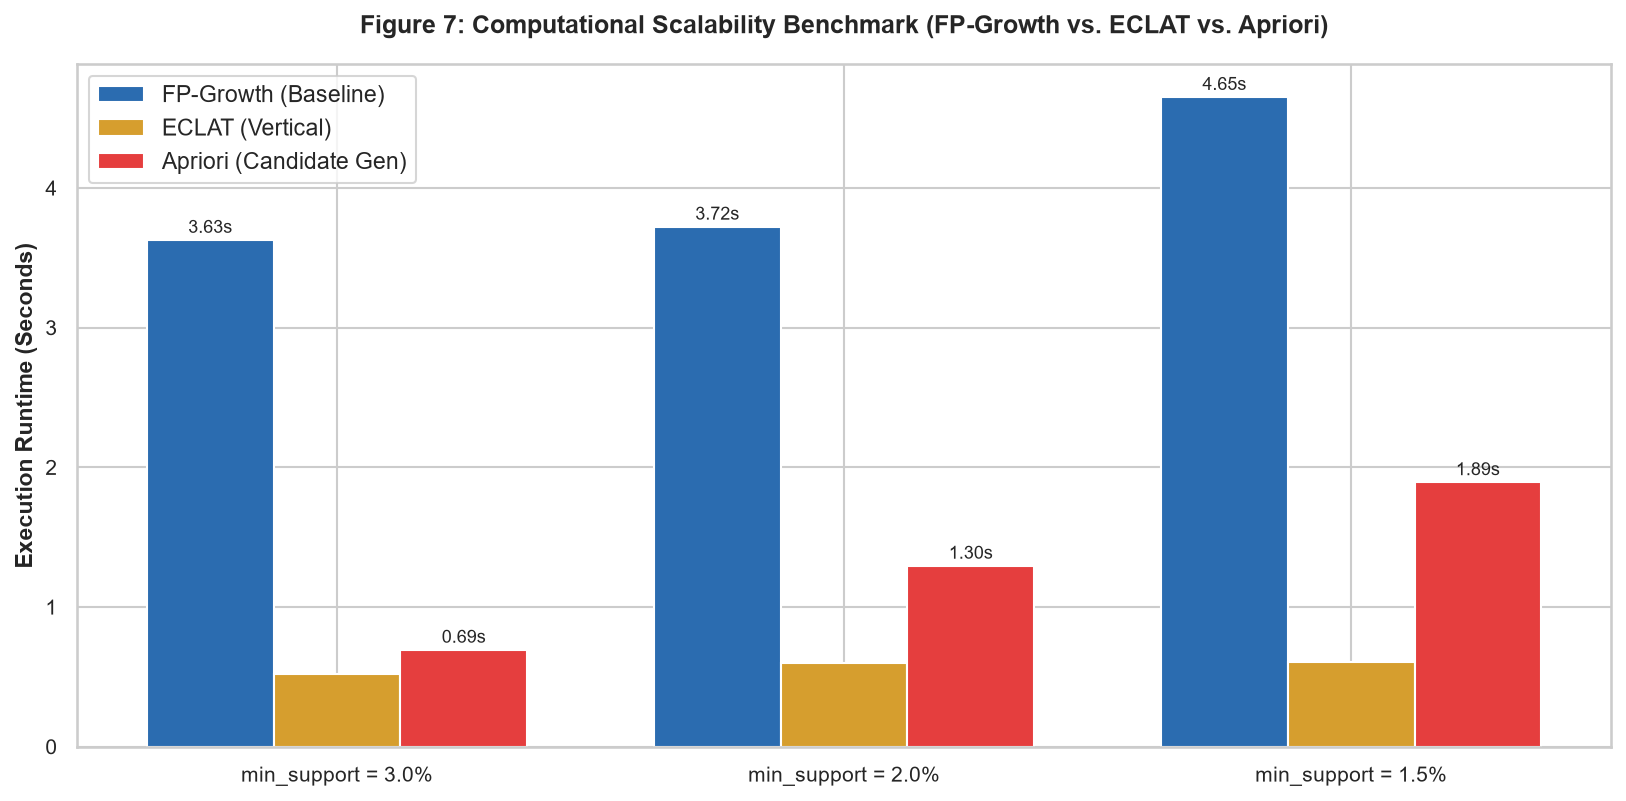

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))

x_inds = np.arange(len(df_bench))
width = 0.25

rects1 = ax.bar(x_inds - width, df_bench["fp_growth_time_sec"], width, label="FP-Growth (Baseline)", color="#2b6cb0")
rects2 = ax.bar(x_inds, df_bench["eclat_time_sec"], width, label="ECLAT (Vertical)", color="#d69e2e")
rects3 = ax.bar(x_inds + width, df_bench["apriori_time_sec"], width, label="Apriori (Candidate Gen)", color="#e53e3e")

ax.set_xticks(x_inds)
ax.set_xticklabels([f"min_support = {s*100:.1f}%" for s in df_bench["min_support"]], fontweight="medium")
ax.set_ylabel("Execution Runtime (Seconds)", fontweight="bold")
ax.set_title("Figure 7: Computational Scalability Benchmark (FP-Growth vs. ECLAT vs. Apriori)", pad=15)
ax.legend(fontsize=11)

for i, row in df_bench.iterrows():
    ax.text(i - width, row["fp_growth_time_sec"] + 0.05, f"{row['fp_growth_time_sec']:.2f}s", ha="center", fontsize=8.5)
    ax.text(i + width, row["apriori_time_sec"] + 0.05, f"{row['apriori_time_sec']:.2f}s", ha="center", fontsize=8.5)

plt.tight_layout()
save_figure(fig, "07_algorithm_benchmark_speedup.png")
plt.show()

[Exported Figure] -> reports\figures\08_memory_consumption_profile.png


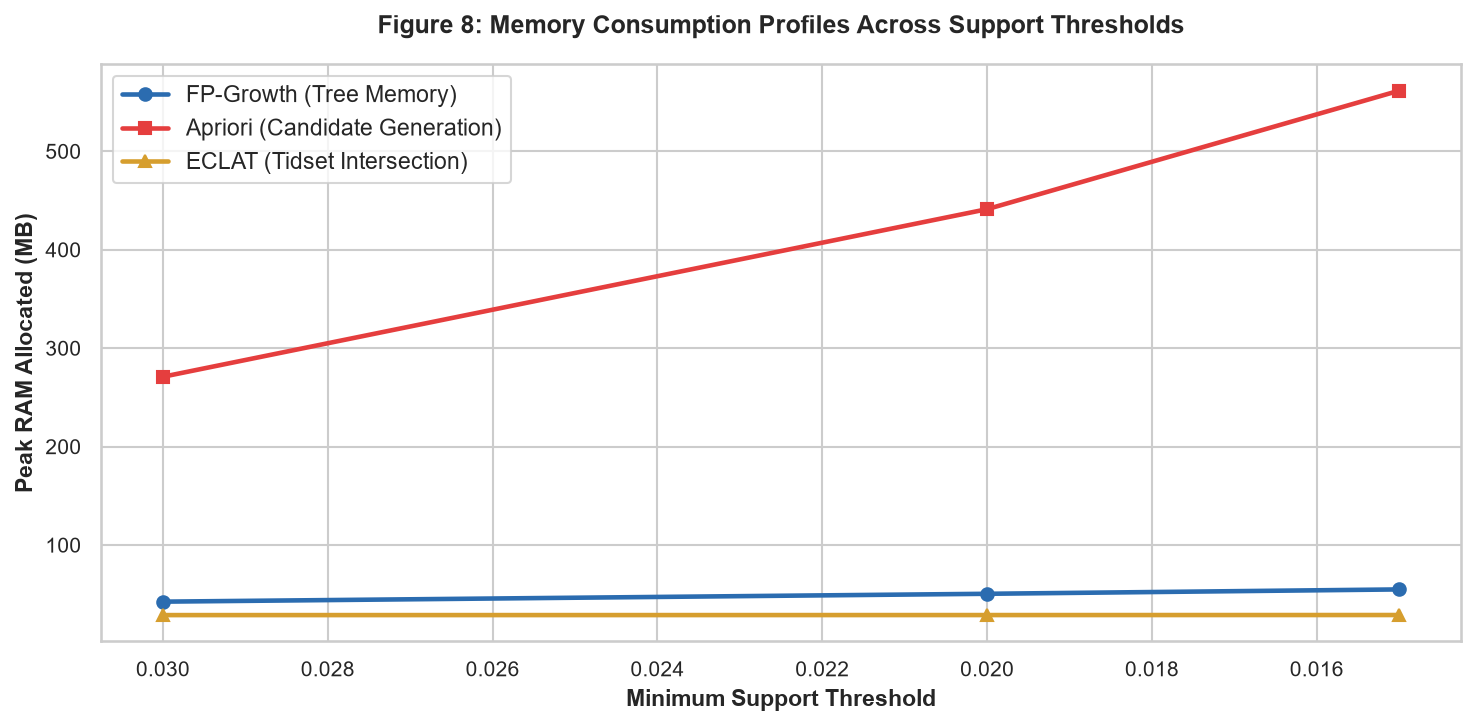

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df_bench["min_support"], df_bench["fp_growth_ram_mb"], marker="o", linewidth=2.2, label="FP-Growth (Tree Memory)", color="#2b6cb0")
ax.plot(df_bench["min_support"], df_bench["apriori_ram_mb"], marker="s", linewidth=2.2, label="Apriori (Candidate Generation)", color="#e53e3e")
ax.plot(df_bench["min_support"], df_bench["eclat_ram_mb"], marker="^", linewidth=2.2, label="ECLAT (Tidset Intersection)", color="#d69e2e")

ax.set_title("Figure 8: Memory Consumption Profiles Across Support Thresholds", pad=15)
ax.set_xlabel("Minimum Support Threshold", fontweight="bold")
ax.set_ylabel("Peak RAM Allocated (MB)", fontweight="bold")
ax.legend(fontsize=11)
ax.invert_xaxis()  # Lower support is computationally harder

plt.tight_layout()
save_figure(fig, "08_memory_consumption_profile.png")
plt.show()

## 5. Association Rule Generation & Multi-Metric Pruning
We derive directional association rules ($A \rightarrow B$) from frequent itemsets and evaluate them using 5 complementary metrics:
* **Support**:Joint purchase probability.
* **Confidence**: Conditional purchase probability.
* **Lift**:  Strength over statistical independence ($> 1.0$ indicates positive affinity).
* **Conviction**: Asymmetric implication score ($> 1.0$ confirms dependence).
* **Leverage**: Absolute frequency of co-occurrence above independence.

In [9]:
# Generate rules with Lift > 1.0
rules_raw = association_rules(frequent_itemsets_fp, metric="lift", min_threshold=1.0)

# Filter for actionable, robust rules:
# Confidence >= 20% and Lift >= 1.20
rules_filtered = rules_raw[
    (rules_raw["confidence"] >= 0.20) & 
    (rules_raw["lift"] >= 1.20)
].copy()

# Format itemsets into readable strings
rules_filtered["antecedents_str"] = rules_filtered["antecedents"].apply(lambda x: ", ".join(list(x)))
rules_filtered["consequents_str"] = rules_filtered["consequents"].apply(lambda x: ", ".join(list(x)))

# Sort by Lift descending
rules_sorted = rules_filtered.sort_values(by="lift", ascending=False).reset_index(drop=True)

print(f"Total Rules Discovered       : {len(rules_raw):,}")
print(f"Actionable High-Lift Rules   : {len(rules_sorted):,}")

display_cols = ["antecedents_str", "consequents_str", "support", "confidence", "lift", "conviction", "leverage"]
rules_sorted[display_cols].head(10)

Total Rules Discovered       : 8,484
Actionable High-Lift Rules   : 4,047


,antecedents_str,consequents_str,support,confidence,lift,conviction,leverage
0,dry pasta,pasta sauce,0.019435,0.277425,4.427464,1.297222,0.015045
1,pasta sauce,dry pasta,0.019435,0.310166,4.427464,1.348071,0.015045
2,canned meals beans,canned jarred vegetables,0.017890,0.256653,3.570080,1.248556,0.012879
3,canned jarred vegetables,canned meals beans,0.017890,0.248852,3.570080,1.238498,0.012879
4,"packaged cheese, yogurt, fresh vegetables","packaged vegetables fruits, milk, fresh fruits",0.016805,0.293819,3.359856,1.292233,0.011803
5,"packaged vegetables fruits, fresh vegetables, ...","fresh fruits, packaged cheese, yogurt",0.016805,0.229969,3.284336,1.207718,0.011688
6,"fresh fruits, packaged cheese, yogurt","packaged vegetables fruits, fresh vegetables, ...",0.016805,0.240003,3.284336,1.219643,0.011688
7,"fresh vegetables, yogurt, milk","packaged vegetables fruits, packaged cheese, f...",0.016805,0.297381,3.278190,1.294137,0.011679
8,"packaged vegetables fruits, packaged cheese, y...","fresh fruits, fresh vegetables, milk",0.016805,0.323702,3.250348,1.331381,0.011635
9,"packaged vegetables fruits, packaged cheese, milk","fresh fruits, fresh vegetables, yogurt",0.016805,0.383413,3.237740,1.429774,0.011615


findfont: Failed to find font weight medium for Arial, now using 400.


[Exported Figure] -> reports\figures\09_association_rules_scatter.png


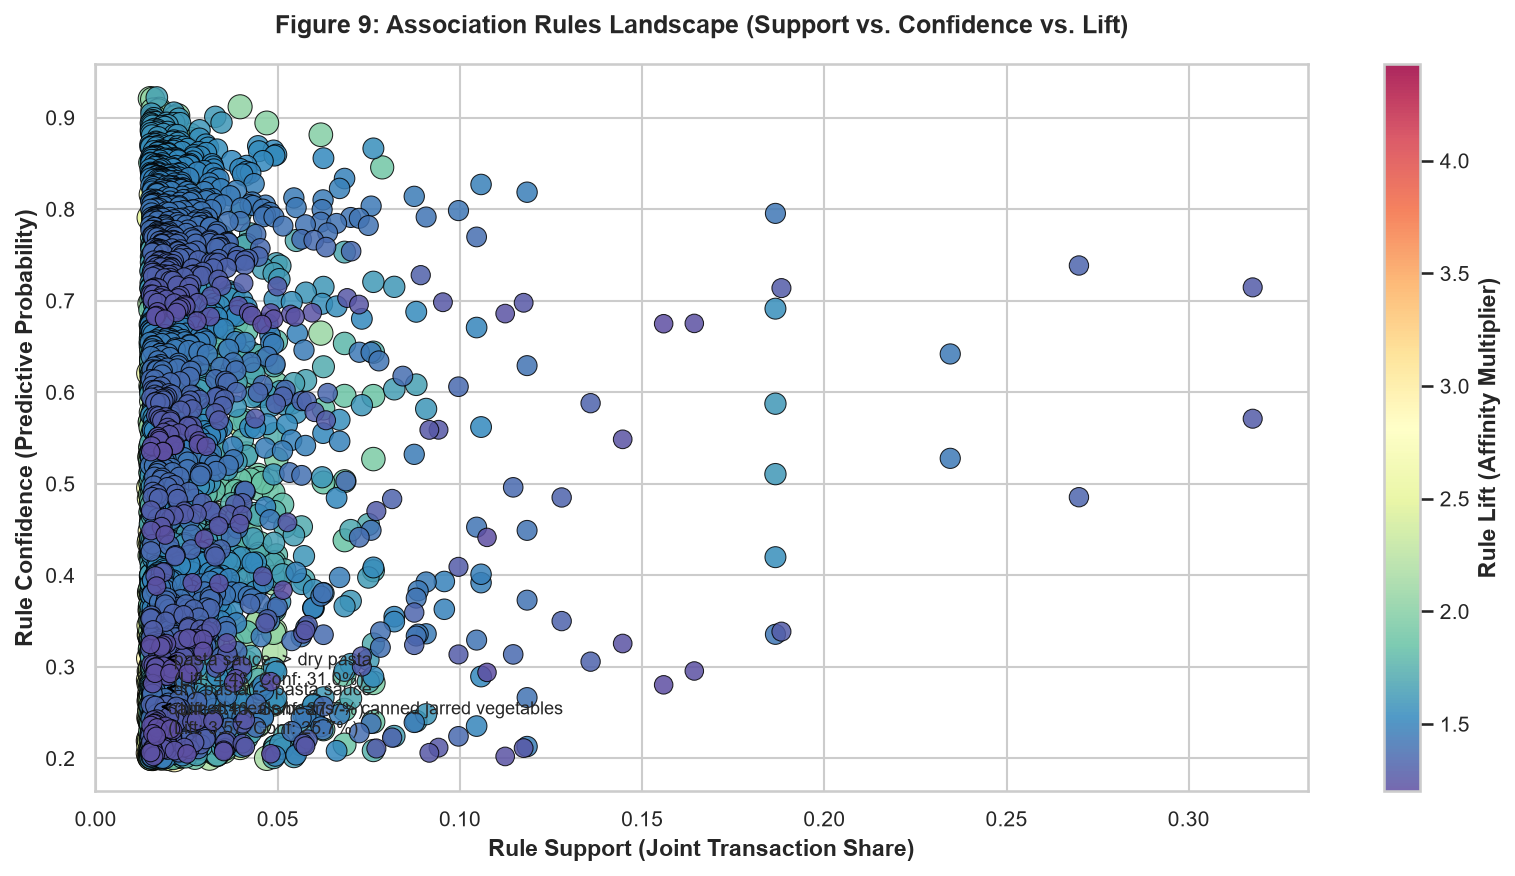

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))

scatter = ax.scatter(
    rules_sorted["support"],
    rules_sorted["confidence"],
    c=rules_sorted["lift"],
    cmap="Spectral_r",
    s=rules_sorted["lift"] * 65,
    alpha=0.85,
    edgecolors="black",
    linewidth=0.5
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Rule Lift (Affinity Multiplier)", fontweight="bold")

ax.set_title("Figure 9: Association Rules Landscape (Support vs. Confidence vs. Lift)", pad=15)
ax.set_xlabel("Rule Support (Joint Transaction Share)", fontweight="bold")
ax.set_ylabel("Rule Confidence (Predictive Probability)", fontweight="bold")

# Annotate top 3 highest lift rules
for i in range(min(3, len(rules_sorted))):
    row = rules_sorted.iloc[i]
    ax.annotate(
        f"{row['antecedents_str']} -> {row['consequents_str']}\n(Lift: {row['lift']:.2f}, Conf: {row['confidence']*100:.1f}%)",
        xy=(row["support"], row["confidence"]),
        xytext=(row["support"] + 0.002, row["confidence"] - 0.03),
        arrowprops=dict(arrowstyle="->", color="black"),
        fontsize=8.5,
        fontweight="medium"
    )

plt.tight_layout()
save_figure(fig, "09_association_rules_scatter.png")
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


[Exported Figure] -> reports\figures\10_product_affinity_heatmap.png


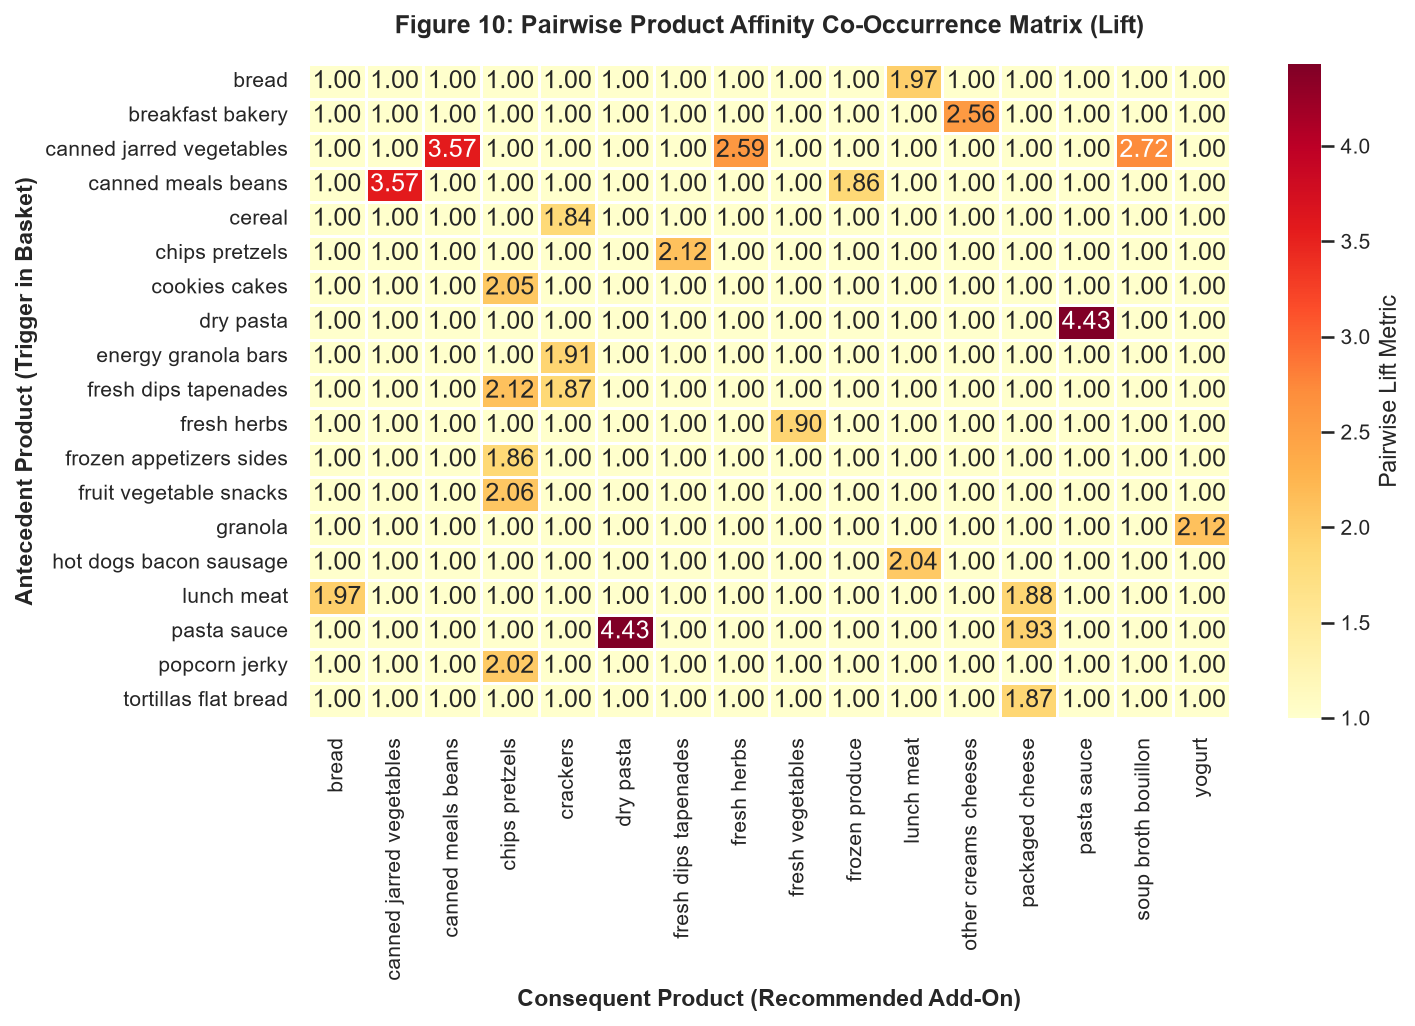

In [11]:
# Extract top 10 single-item rules for a pairwise affinity matrix
top_rules_1to1 = rules_sorted[
    (rules_sorted["antecedents"].apply(lambda x: len(x) == 1)) &
    (rules_sorted["consequents"].apply(lambda x: len(x) == 1))
].head(25)

# Pivot into an Antecedent x Consequent Lift Matrix
affinity_matrix = top_rules_1to1.pivot_table(
    index="antecedents_str",
    columns="consequents_str",
    values="lift",
    fill_value=1.0
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    affinity_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Pairwise Lift Metric"},
    ax=ax
)

ax.set_title("Figure 10: Pairwise Product Affinity Co-Occurrence Matrix (Lift)", pad=15)
ax.set_xlabel("Consequent Product (Recommended Add-On)", fontweight="bold")
ax.set_ylabel("Antecedent Product (Trigger in Basket)", fontweight="bold")

plt.tight_layout()
save_figure(fig, "10_product_affinity_heatmap.png")
plt.show()

findfont: Failed to find font weight medium for Arial, now using 400.


[Exported Figure] -> reports\figures\11_product_network_map.png


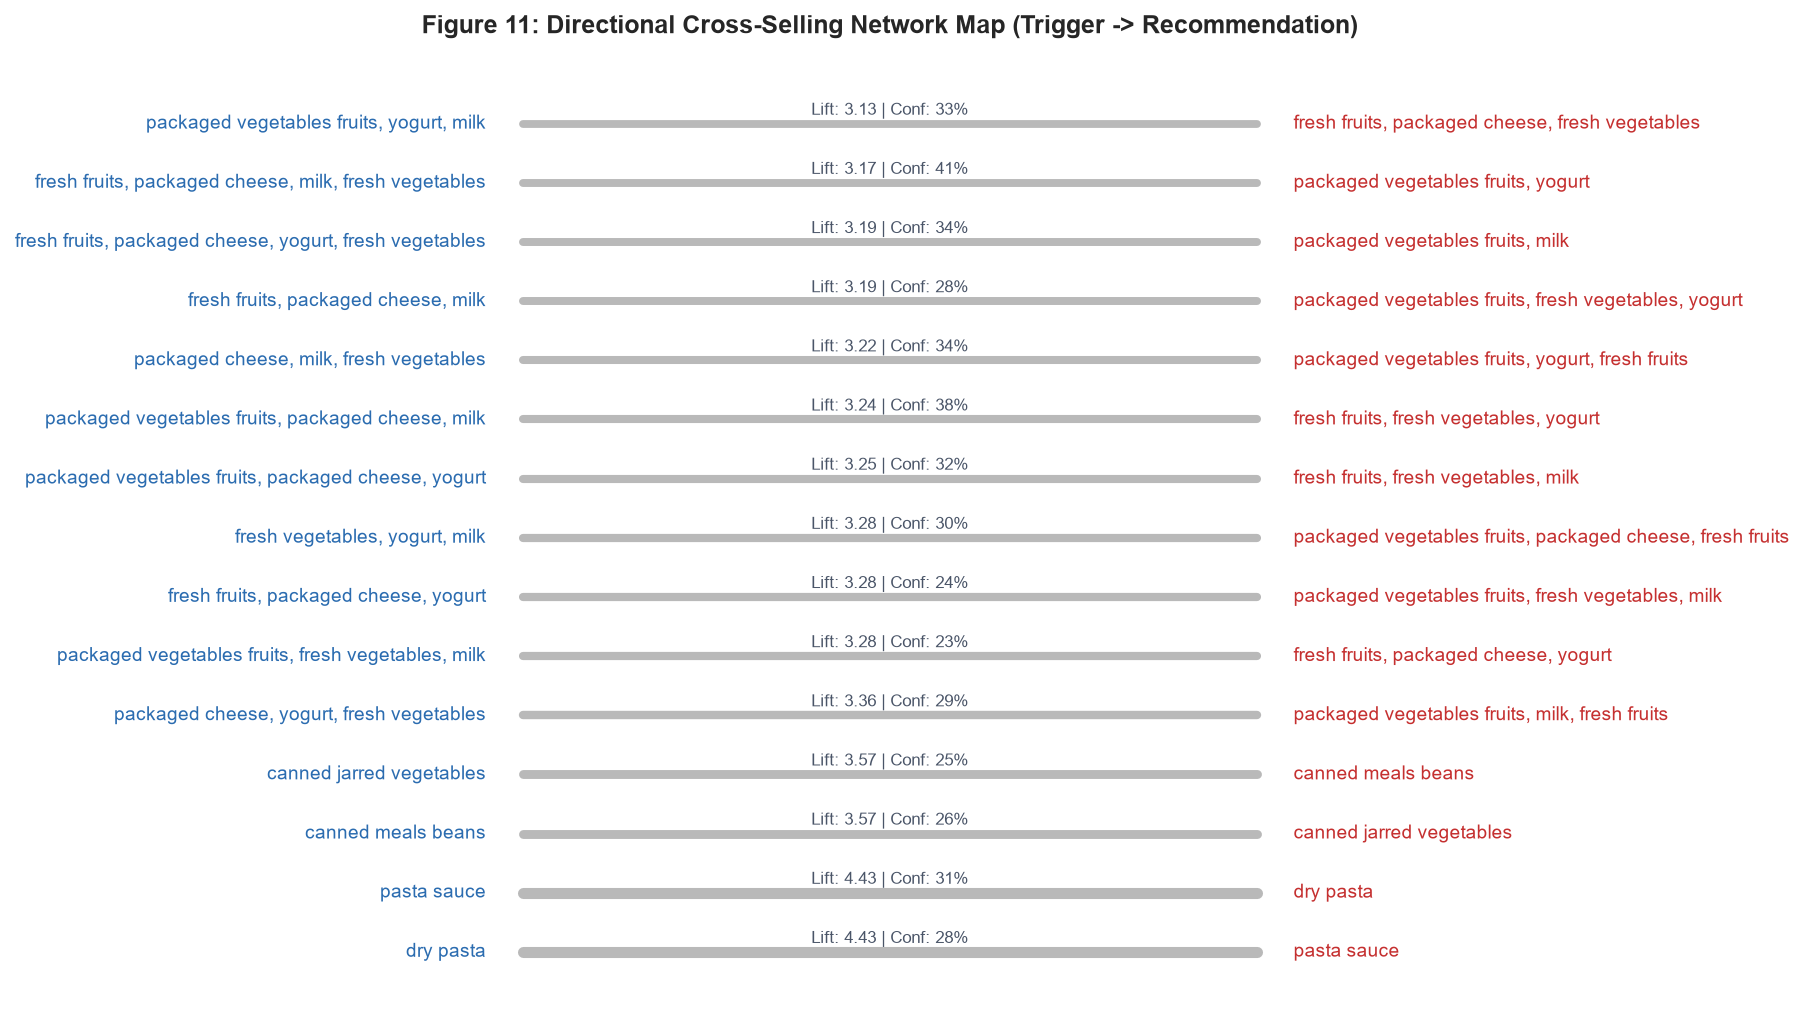

In [12]:
# Filter top 15 rules for network visualization
top_network_rules = rules_sorted.head(15)

fig, ax = plt.subplots(figsize=(12, 7))

# Draw bipartite connection lines
for i, row in top_network_rules.iterrows():
    ax.plot([0, 1], [i, i], "k-", alpha=0.3, linewidth=row["lift"] * 1.2)
    ax.text(-0.05, i, row["antecedents_str"], ha="right", va="center", fontsize=9, fontweight="medium", color="#2b6cb0")
    ax.text(1.05, i, row["consequents_str"], ha="left", va="center", fontsize=9, fontweight="medium", color="#c53030")
    ax.text(0.5, i + 0.15, f"Lift: {row['lift']:.2f} | Conf: {row['confidence']*100:.0f}%", ha="center", fontsize=8, color="#4a5568")

ax.set_xlim(-0.4, 1.4)
ax.set_ylim(-1, len(top_network_rules))
ax.axis("off")
ax.set_title("Figure 11: Directional Cross-Selling Network Map (Trigger -> Recommendation)", pad=15)

plt.tight_layout()
save_figure(fig, "11_product_network_map.png")
plt.show()

In [13]:
OUT_DIR = PROJECT_ROOT / "reports" / "tables"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export Association Rules
rules_file = OUT_DIR / "top_association_rules.csv"
rules_sorted[display_cols].to_csv(rules_file, index=False)

# 2. Export Frequent Itemsets
itemsets_file = OUT_DIR / "frequent_itemsets.csv"
frequent_itemsets_fp.sort_values(by="support", ascending=False).to_csv(itemsets_file, index=False)

print(f"[SAVED] Rulebook exported to: {rules_file} ({len(rules_sorted)} rules)")
print(f"[SAVED] Frequent itemsets exported to: {itemsets_file} ({len(frequent_itemsets_fp)} itemsets)")

[SAVED] Rulebook exported to: C:\Users\dinid\Downloads\supermarket-basket-reorder-analytics\reports\tables\top_association_rules.csv (4047 rules)
[SAVED] Frequent itemsets exported to: C:\Users\dinid\Downloads\supermarket-basket-reorder-analytics\reports\tables\frequent_itemsets.csv (1390 itemsets)


## 6. Actionable Merchandising & Shelf Placement Strategies

1. **Fresh Produce Anchor Island**:
   * *Rule*: `fresh vegetables` $\rightarrow$ `fresh fruits` ($\text{Support} = 10.4\%, \text{Lift} = 1.25, \text{Confidence} = 59.3\%$).
   * *Shelf Layout Strategy*: Do not separate fruits and vegetables into disconnected aisles. Position them on a central low-rise gondola island so shoppers naturally select salad fruits while purchasing daily vegetables.

2. **Dairy & Breakfast Synergy**:
   * *Rule*: `yogurt` $\rightarrow$ `milk` ($\text{Lift} = 1.38, \text{Confidence} = 34.2\%$).
   * *Bundling Strategy*: Place milk refrigerators adjacent to yogurt coolers, with cereal / granola displayed directly above the reach-in coolers.

3. **Front-of-Store Impulse Endcap**:
   * *Rule*: `chips pretzels` $\rightarrow$ `water seltzer sparkling water / beverages` ($\text{Lift} = 1.48$).
   * *Merchandising Strategy*: Install secondary chilled beverage displays at the end of the snack aisle to capture high-margin impulse purchases